# Separating signal eigenvalues from noise

The Marcenko-Pastur density describes the limiting eigenvalue spread of a covariance matrix formed from independent noise:

$$
f(\lambda)=\frac{q}{2\pi\sigma^2\lambda}
\sqrt{(\lambda_+-\lambda)(\lambda-\lambda_-)},
\qquad
\lambda_{\pm}=\sigma^2\left(1\pm q^{-1/2}\right)^2,
\qquad q=\frac{T}{N}>1.
$$

Here, $\lambda$ is an eigenvalue; $f(\lambda)$ is its density; $\sigma^2$ is the fitted noise variance. $\lambda_-$ and $\lambda_+$ are the lower and upper noise boundaries; $T$ is observation count; $N$ is variable count; $q=T/N.$ $\pi$ is the circle constant, and the formula applies on $[\lambda_-,\lambda_+]$ under the stated large-sample noise model.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib
import io
import zipfile

DATA_URL = "https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/49_Industry_Portfolios_daily_CSV.zip"
DATA_DIR = ROOT / "data" / "public" / "ken_french"
DATA_PATH = ensure_dataset(ROOT, "french_49_industries")
EXPECTED_DATA_HASH = "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == EXPECTED_DATA_HASH
with zipfile.ZipFile(DATA_PATH) as archive:
    archive_name = archive.namelist()[0]
    public_lines = archive.read(archive_name).decode("latin1").splitlines()
header_row = next(index for index, line in enumerate(public_lines) if line.startswith(",Agric"))
end_row = next(index for index in range(header_row + 1, len(public_lines)) if not public_lines[index].strip())
raw = pd.read_csv(io.StringIO("\n".join(public_lines[header_row:end_row])))
raw = raw.rename(columns={raw.columns[0]: "Date"})
raw["Date"] = pd.to_datetime(raw["Date"].astype(str), format="%Y%m%d")
raw = raw.set_index("Date").replace([-99.99, -999.0], np.nan) / 100.0
industry_returns = raw.loc["2019-01-01":"2025-12-31"].dropna().copy()

from RiskLabAI.data.denoise import corr_to_cov, cov_to_corr, denoise_cov, denoised_corr, denoised_corr2, find_max_eval, fit_kde, marcenko_pastur_pdf, nercome_denoised_covariance, optimal_portfolio, pca
from RiskLabAI.data.denoise.denoising import optimal_portfolio_denoised

FIGURES = ROOT / "outputs" / "figures" / "10_covariance_denoising"
TABLES = ROOT / "outputs" / "tables" / "10_covariance_denoising"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Fitting a Noise Boundary

In [2]:
snapshot = industry_returns.loc[:"2024-12-31"].tail(125)
observation_count, portfolio_count = snapshot.shape
q_ratio = observation_count / portfolio_count
sample_covariance = np.cov(snapshot.to_numpy(), rowvar=False)
sample_standard_deviation = np.sqrt(np.diag(sample_covariance))
sample_correlation = cov_to_corr(sample_covariance)
raw_eigenvalues, raw_eigenvectors = pca(sample_correlation)
bandwidth = 0.05
lambda_max, fitted_variance = find_max_eval(np.diag(raw_eigenvalues), q_ratio, bandwidth)
lambda_min = fitted_variance * (1.0 - q_ratio ** -0.5) ** 2
signal_count = int(np.sum(raw_eigenvalues > lambda_max))
noise_count = portfolio_count - signal_count
mp_fit_summary = pd.DataFrame({
    "Quantity": ["Observations", "Portfolios", "Observation to portfolio ratio", "Kernel bandwidth", "Fitted noise variance", "Lower noise boundary", "Upper noise boundary", "Signal eigenvalues", "Noise eigenvalues"],
    "Value": [observation_count, portfolio_count, q_ratio, bandwidth, fitted_variance, lambda_min, lambda_max, signal_count, noise_count],
})
save_table(mp_fit_summary, "mp_fit_summary", "Fitted random-matrix noise boundary for the 125-day public window.", "tab:chapter9-mp-fit", fit=True)
display(mp_fit_summary.round(6))

theoretical_density = marcenko_pastur_pdf(fitted_variance, q_ratio, num_points=500)
density_grid = theoretical_density.index.to_numpy()
empirical_density = np.exp(fit_kde(raw_eigenvalues, bandwidth=bandwidth).score_samples(density_grid.reshape(-1, 1)))

,Quantity,Value
0,Observations,125
1,Portfolios,49
2,Observation to portfolio ratio,2.551020
3,Kernel bandwidth,0.050000
4,Fitted noise variance,0.500786
5,Lower noise boundary,0.070011
6,Upper noise boundary,1.324178
7,Signal eigenvalues,5
8,Noise eigenvalues,44


## Comparing two covariance cleaning methods

Constant residual cleaning keeps the leading signal eigenvalues and replaces every noise eigenvalue by their average:

$$
\widetilde\lambda_j=
\begin{cases}
\lambda_j,&j\leq K,\\
\displaystyle\frac{1}{N-K}\sum_{k=K+1}^{N}\lambda_k,&j>K,
\end{cases}
\qquad
\widetilde C_{\mathrm{const}}=Q\widetilde\Lambda Q^{\mathsf T}.
$$

Here, $\lambda_j$ is ordered eigenvalue $j$; $K$ is the number above the fitted noise boundary; $N$ is matrix size. $\widetilde\lambda_j$ is a cleaned eigenvalue; $Q$ contains the original eigenvectors; $\widetilde\Lambda$ contains cleaned eigenvalues. $\widetilde C_{\mathrm{const}}$ is the reconstructed matrix, rescaled afterward to unit diagonal.

Targeted shrinkage keeps the signal part and reduces only the off-diagonal contribution assigned to noise:

$$
\widetilde C_{\alpha}
=Q_L\Lambda_LQ_L^{\mathsf T}
+\alpha Q_R\Lambda_RQ_R^{\mathsf T}
+(1-\alpha)\operatorname{diag}\!\left(Q_R\Lambda_RQ_R^{\mathsf T}\right),
\qquad 0\leq\alpha\leq1.
$$

Here, $Q_L,\Lambda_L$ contain the leading signal eigenvectors and eigenvalues; $Q_R,\Lambda_R$ contain the remaining noise part. $\operatorname{diag}(A)$ keeps only the diagonal of $A$; $\alpha$ is the retained share of the noise off-diagonal contribution. $\widetilde C_{\alpha}$ is the cleaned matrix; $\alpha=0$ gives full targeted shrinkage and $\alpha=1$ returns the original matrix.

,Method,Smallest eigenvalue,Largest eigenvalue,Condition number,Trace,Change from sample
0,Sample,0.024725,21.991155,889.447608,49,0
1,Constant residual,0.292923,21.247162,72.535082,49,2.775653
2,"Targeted, alpha 0",0.111183,22.271787,200.317169,49,2.073287
3,"Targeted, alpha 0.5",0.083456,22.131345,265.185230,49,1.036644


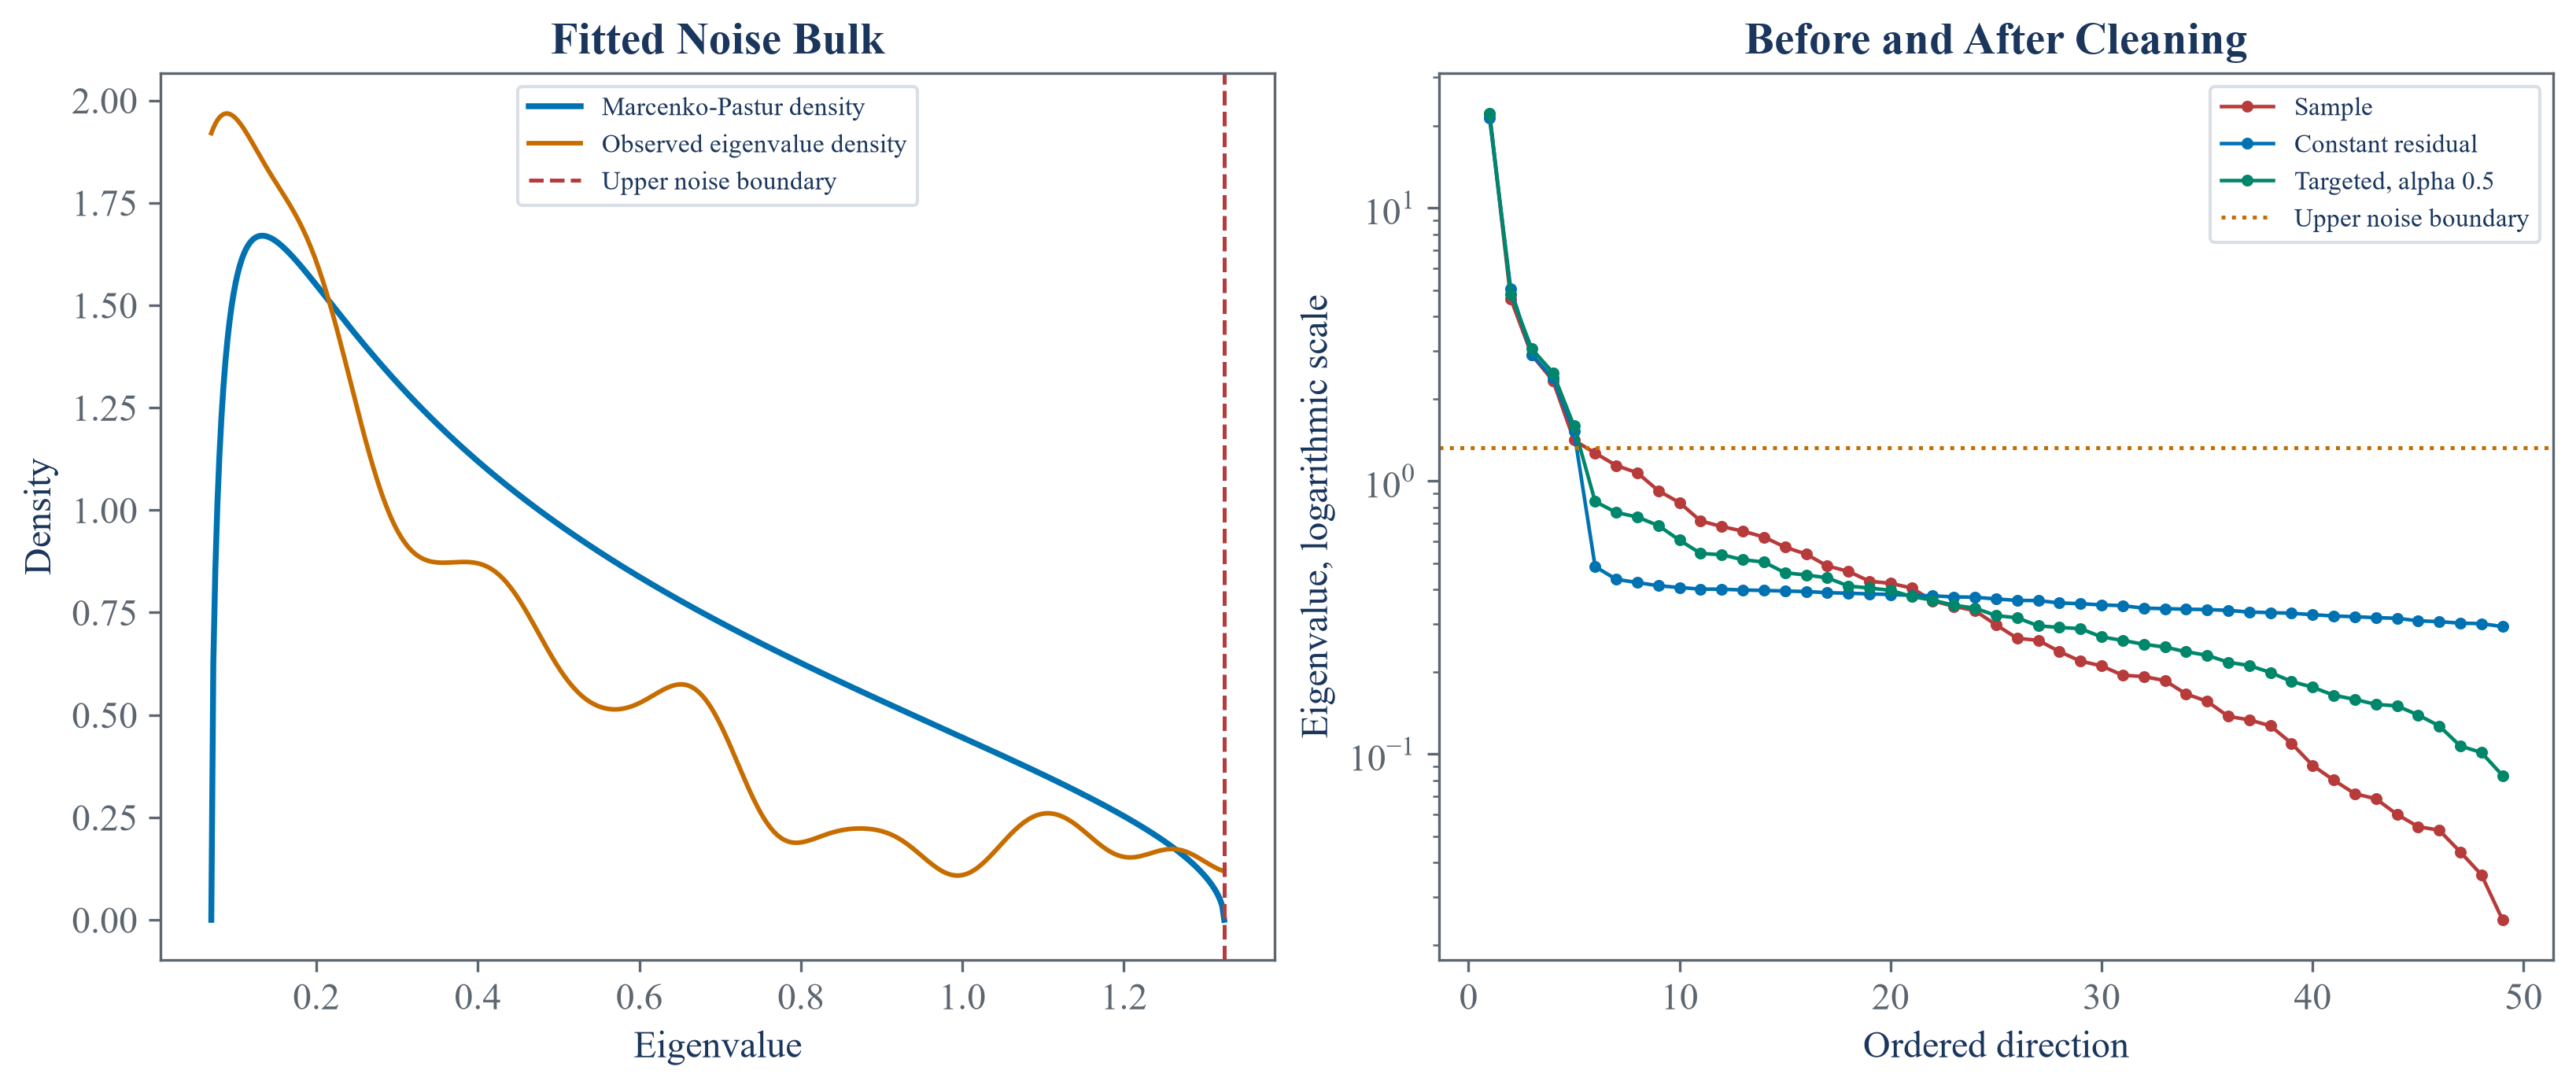

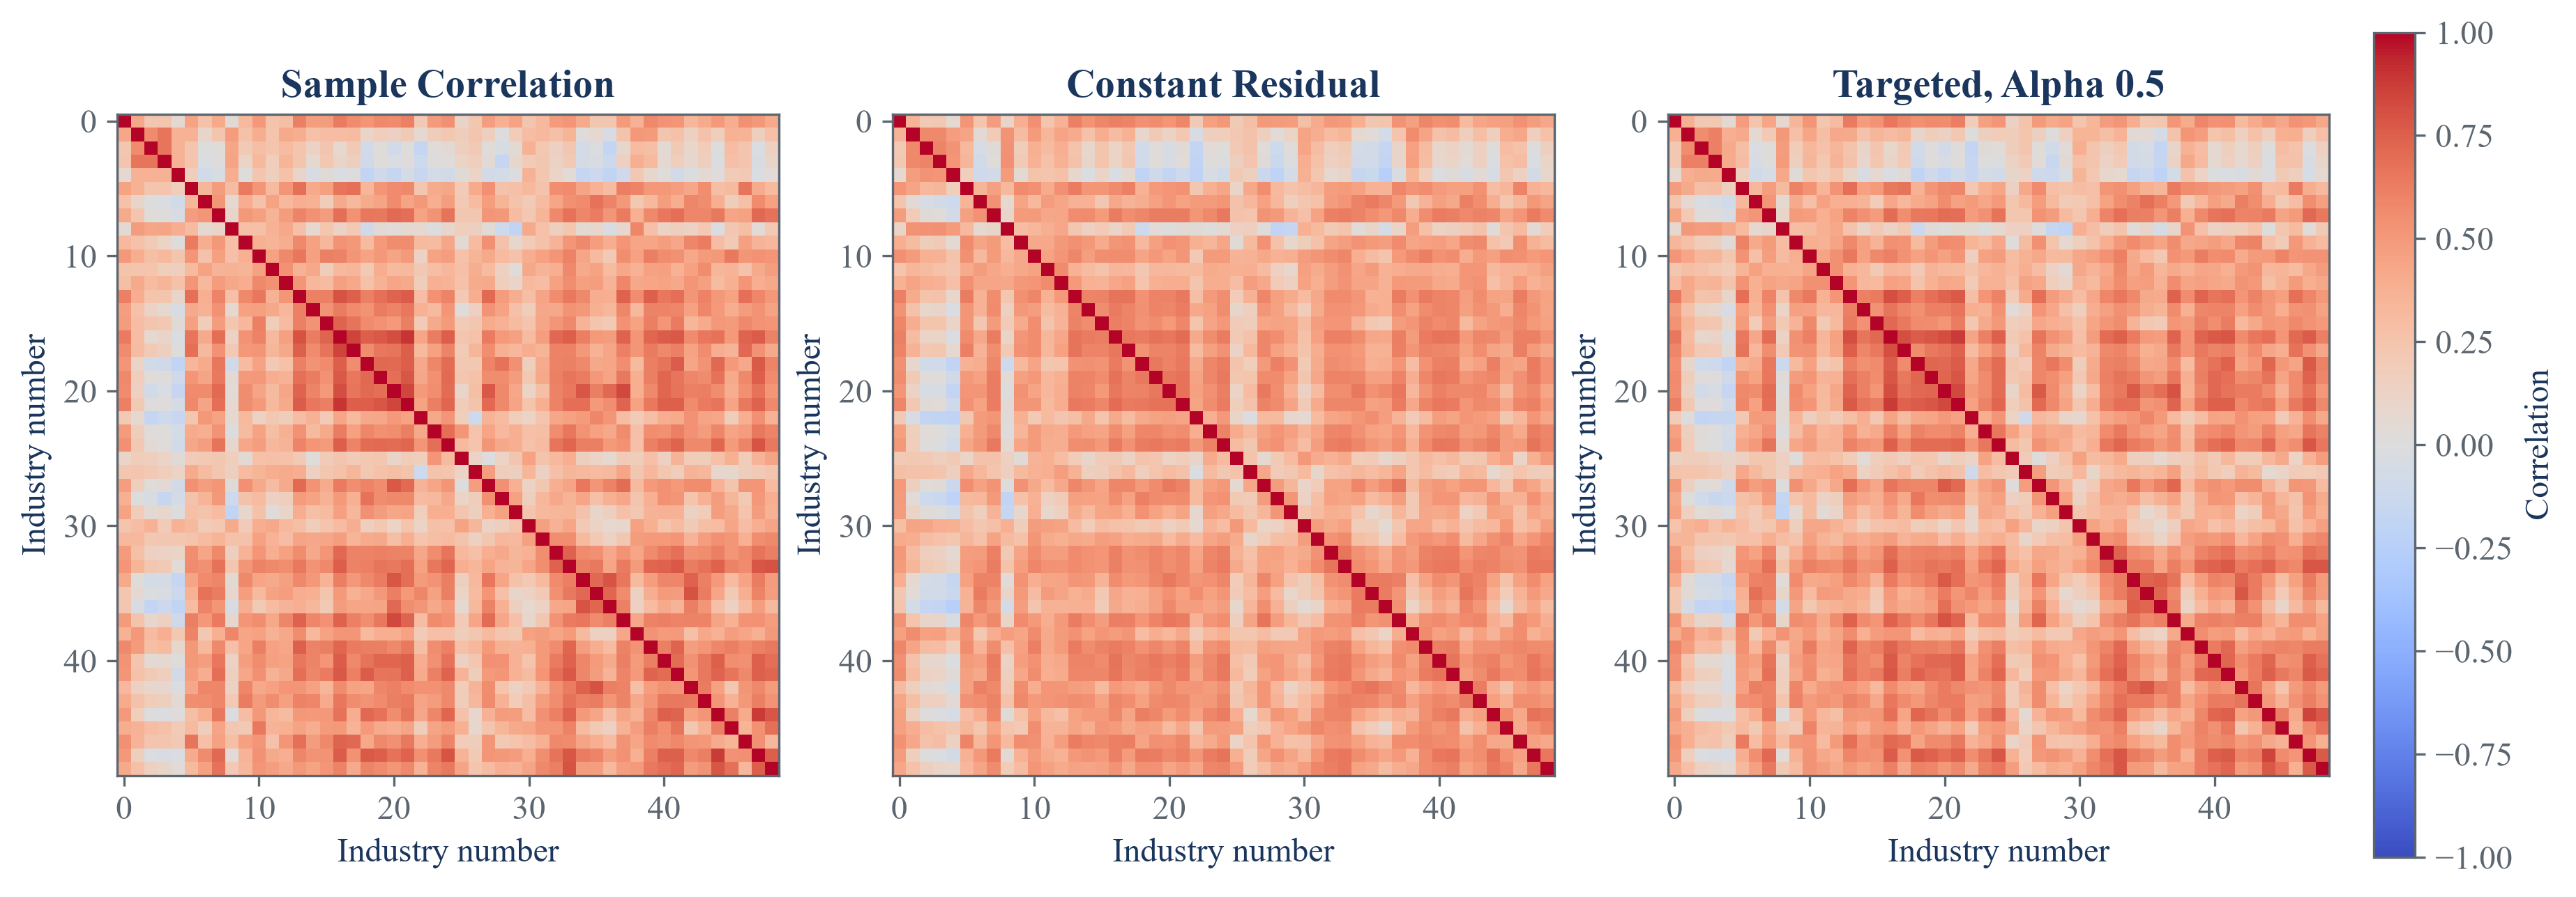

In [3]:
constant_correlation = denoised_corr(np.diag(raw_eigenvalues), raw_eigenvectors, signal_count)
constant_covariance = corr_to_cov(constant_correlation, sample_standard_deviation)
targeted_full_correlation = denoised_corr2(np.diag(raw_eigenvalues), raw_eigenvectors, signal_count, alpha=0.0)
targeted_half_correlation = denoised_corr2(np.diag(raw_eigenvalues), raw_eigenvectors, signal_count, alpha=0.5)
targeted_full_covariance = corr_to_cov(targeted_full_correlation, sample_standard_deviation)
targeted_half_covariance = corr_to_cov(targeted_half_correlation, sample_standard_deviation)
method_covariances = {
    "Sample": sample_covariance,
    "Constant residual": constant_covariance,
    "Targeted, alpha 0": targeted_full_covariance,
    "Targeted, alpha 0.5": targeted_half_covariance,
}
matrix_rows = []
for method, covariance in method_covariances.items():
    current_correlation = cov_to_corr(covariance)
    current_eigenvalues = np.linalg.eigvalsh(current_correlation)
    matrix_rows.append({"Method": method, "Smallest eigenvalue": current_eigenvalues.min(), "Largest eigenvalue": current_eigenvalues.max(), "Condition number": current_eigenvalues.max() / current_eigenvalues.min(), "Trace": np.trace(current_correlation), "Change from sample": np.linalg.norm(current_correlation - sample_correlation, ord="fro")})
denoising_matrix_summary = pd.DataFrame(matrix_rows)
save_table(denoising_matrix_summary, "denoising_matrix_summary", "Spectral properties of the public sample and three cleaned estimates.", "tab:chapter9-denoising-matrix", fit=True)
display(denoising_matrix_summary.round(6))

figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.5), constrained_layout=True)
axes[0].plot(density_grid, theoretical_density.to_numpy(), color=palette["cyan"], linewidth=1.8, label="Marcenko-Pastur density")
axes[0].plot(density_grid, empirical_density, color=palette["amber"], linewidth=1.4, label="Observed eigenvalue density")
axes[0].axvline(lambda_max, color=palette["rose"], linestyle="--", linewidth=1.2, label="Upper noise boundary")
axes[0].set_title("Fitted Noise Bulk")
axes[0].set_xlabel("Eigenvalue")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=8)
for method, covariance, color in [("Sample", sample_covariance, palette["rose"]), ("Constant residual", constant_covariance, palette["cyan"]), ("Targeted, alpha 0.5", targeted_half_covariance, palette["green"])]:
    values = np.linalg.eigvalsh(cov_to_corr(covariance))[::-1]
    axes[1].plot(np.arange(1, portfolio_count + 1), values, marker="o", markersize=2.6, linewidth=1.1, color=color, label=method)
axes[1].axhline(lambda_max, color=palette["amber"], linestyle=":", linewidth=1.2, label="Upper noise boundary")
axes[1].set_yscale("log")
axes[1].set_title("Before and After Cleaning")
axes[1].set_xlabel("Ordered direction")
axes[1].set_ylabel("Eigenvalue, logarithmic scale")
axes[1].legend(fontsize=8)
figure.savefig(FIGURES / "mp_noise_bulk.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "mp_noise_bulk.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "mp_noise_bulk.png")))
plt.close(figure)

figure, axes = plt.subplots(1, 3, figsize=(12.2, 4.2), constrained_layout=True)
for axis, (matrix, title) in zip(axes, [(sample_correlation, "Sample Correlation"), (constant_correlation, "Constant Residual"), (targeted_half_correlation, "Targeted, Alpha 0.5")]):
    image = axis.imshow(matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0)
    axis.set_title(title)
    axis.set_xlabel("Industry number")
    axis.set_ylabel("Industry number")
figure.colorbar(image, ax=axes, fraction=0.025, pad=0.02, label="Correlation")
figure.savefig(FIGURES / "denoised_correlation_matrices.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "denoised_correlation_matrices.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "denoised_correlation_matrices.png")))
plt.close(figure)

## Error with Known Truth

Relative Frobenius error compares an estimated covariance with a known population covariance on a common scale:

$$
\mathcal E(\widehat\Sigma,\Sigma_0)
=\frac{\lVert\widehat\Sigma-\Sigma_0\rVert_F}{\lVert\Sigma_0\rVert_F}.
$$

Here, $\widehat\Sigma$ is an estimated covariance; $\Sigma_0$ is the covariance used to generate the simulated returns. $\lVert A\rVert_F=\sqrt{\sum_{i,j}A_{ij}^2}$ is the Frobenius norm; $\mathcal E$ is dimensionless relative error.

In [4]:
block_size = 7
block_count = 7
block_correlation = 0.35
block = (1.0 - block_correlation) * np.eye(block_size) + block_correlation * np.ones((block_size, block_size))
true_correlation = np.kron(np.eye(block_count), block)
true_standard_deviation = industry_returns.std(ddof=1).to_numpy()
true_covariance = corr_to_cov(true_correlation, true_standard_deviation)
simulation_rows = []
repetition_count = 40
for repetition in range(repetition_count):
    rng = np.random.default_rng(9000 + repetition)
    simulated_returns = rng.multivariate_normal(np.zeros(portfolio_count), true_covariance, size=observation_count)
    simulated_sample = np.cov(simulated_returns, rowvar=False)
    simulated_clean = denoise_cov(simulated_sample, q_ratio, bandwidth=bandwidth)
    simulated_corr = cov_to_corr(simulated_sample)
    simulated_values, simulated_vectors = pca(simulated_corr)
    simulated_cutoff, _ = find_max_eval(np.diag(simulated_values), q_ratio, bandwidth)
    simulated_factors = int(np.sum(simulated_values > simulated_cutoff))
    simulated_targeted_corr = denoised_corr2(np.diag(simulated_values), simulated_vectors, simulated_factors, alpha=0.5)
    simulated_targeted = corr_to_cov(simulated_targeted_corr, np.sqrt(np.diag(simulated_sample)))
    for method, estimate in [("Sample", simulated_sample), ("Constant residual", simulated_clean), ("Targeted, alpha 0.5", simulated_targeted)]:
        simulation_rows.append({"Repetition": repetition + 1, "Method": method, "Relative covariance error": np.linalg.norm(estimate - true_covariance, ord="fro") / np.linalg.norm(true_covariance, ord="fro"), "Condition number": np.linalg.cond(cov_to_corr(estimate))})
simulation_results = pd.DataFrame(simulation_rows)
raw_errors = simulation_results.loc[simulation_results["Method"] == "Sample"].set_index("Repetition")["Relative covariance error"]
summary_rows = []
for method, group in simulation_results.groupby("Method", sort=False):
    current = group.set_index("Repetition")["Relative covariance error"]
    summary_rows.append({"Method": method, "Mean relative error": current.mean(), "Median relative error": current.median(), "Error standard deviation": current.std(ddof=1), "Mean condition number": group["Condition number"].mean(), "Share beating sample": np.mean(current.to_numpy() < raw_errors.to_numpy()) if method != "Sample" else np.nan})
known_truth_denoising_summary = pd.DataFrame(summary_rows)
save_table(known_truth_denoising_summary, "known_truth_denoising_summary", "Known-truth covariance error across forty fixed-seed repetitions.", "tab:chapter9-known-truth", fit=True)
display(known_truth_denoising_summary.round(6))

,Method,Mean relative error,Median relative error,Error standard deviation,Mean condition number,Share beating sample
0,Sample,0.446924,0.442323,0.026118,41.864440,NaN
1,Constant residual,0.375941,0.373810,0.027622,8.289940,1
2,"Targeted, alpha 0.5",0.433916,0.427414,0.033159,16.317091,0.9


## Slowly Decaying Spectrum

Each repetition learns directions from one sample part, measures their variances on the other part, and the final estimate averages those repetitions:

$$
\widehat\Sigma_b
=P_b\operatorname{diag}\!\left(P_b^{\mathsf T}S_{2,b}P_b\right)P_b^{\mathsf T},
\qquad
\widehat\Sigma_{\mathrm N}=\frac{1}{B}\sum_{b=1}^{B}\widehat\Sigma_b.
$$

Here, $b$ indexes a sample split; $P_b$ contains eigenvectors from the first part; $S_{2,b}$ is covariance from the second part. $\operatorname{diag}(P_b^{\mathsf T}S_{2,b}P_b)$ keeps the measured variance along each direction; $B$ is the number of splits; $\widehat\Sigma_{\mathrm N}$ is the averaged estimate.

Weights are chosen from estimate $m$, then their variance is measured under the known covariance that generated the returns:

$$
V_m=w_m^{\mathsf T}\Sigma_0w_m,
\qquad
w_m=\frac{\widehat\Sigma_m^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\widehat\Sigma_m^{-1}\mathbf 1}.
$$

Here, $m$ names a covariance estimate; $\widehat\Sigma_m$ is that estimate; $w_m$ is its minimum-variance weight vector. $\Sigma_0$ is the known covariance; $V_m$ is realized true variance; $\mathbf 1$ is a vector of ones; $\mathsf T$ denotes transpose.

,Method,Mean relative covariance error,Median relative covariance error,Mean condition number,Mean realized true variance,Median realized true variance
0,NERCOME split average,0.432766,0.417423,17.757221,0.017653,0.017136
1,Random-matrix clipping,0.533020,0.524746,16.517647,0.020969,0.021165
2,Raw sample,0.475696,0.463348,117.800198,0.020114,0.018709


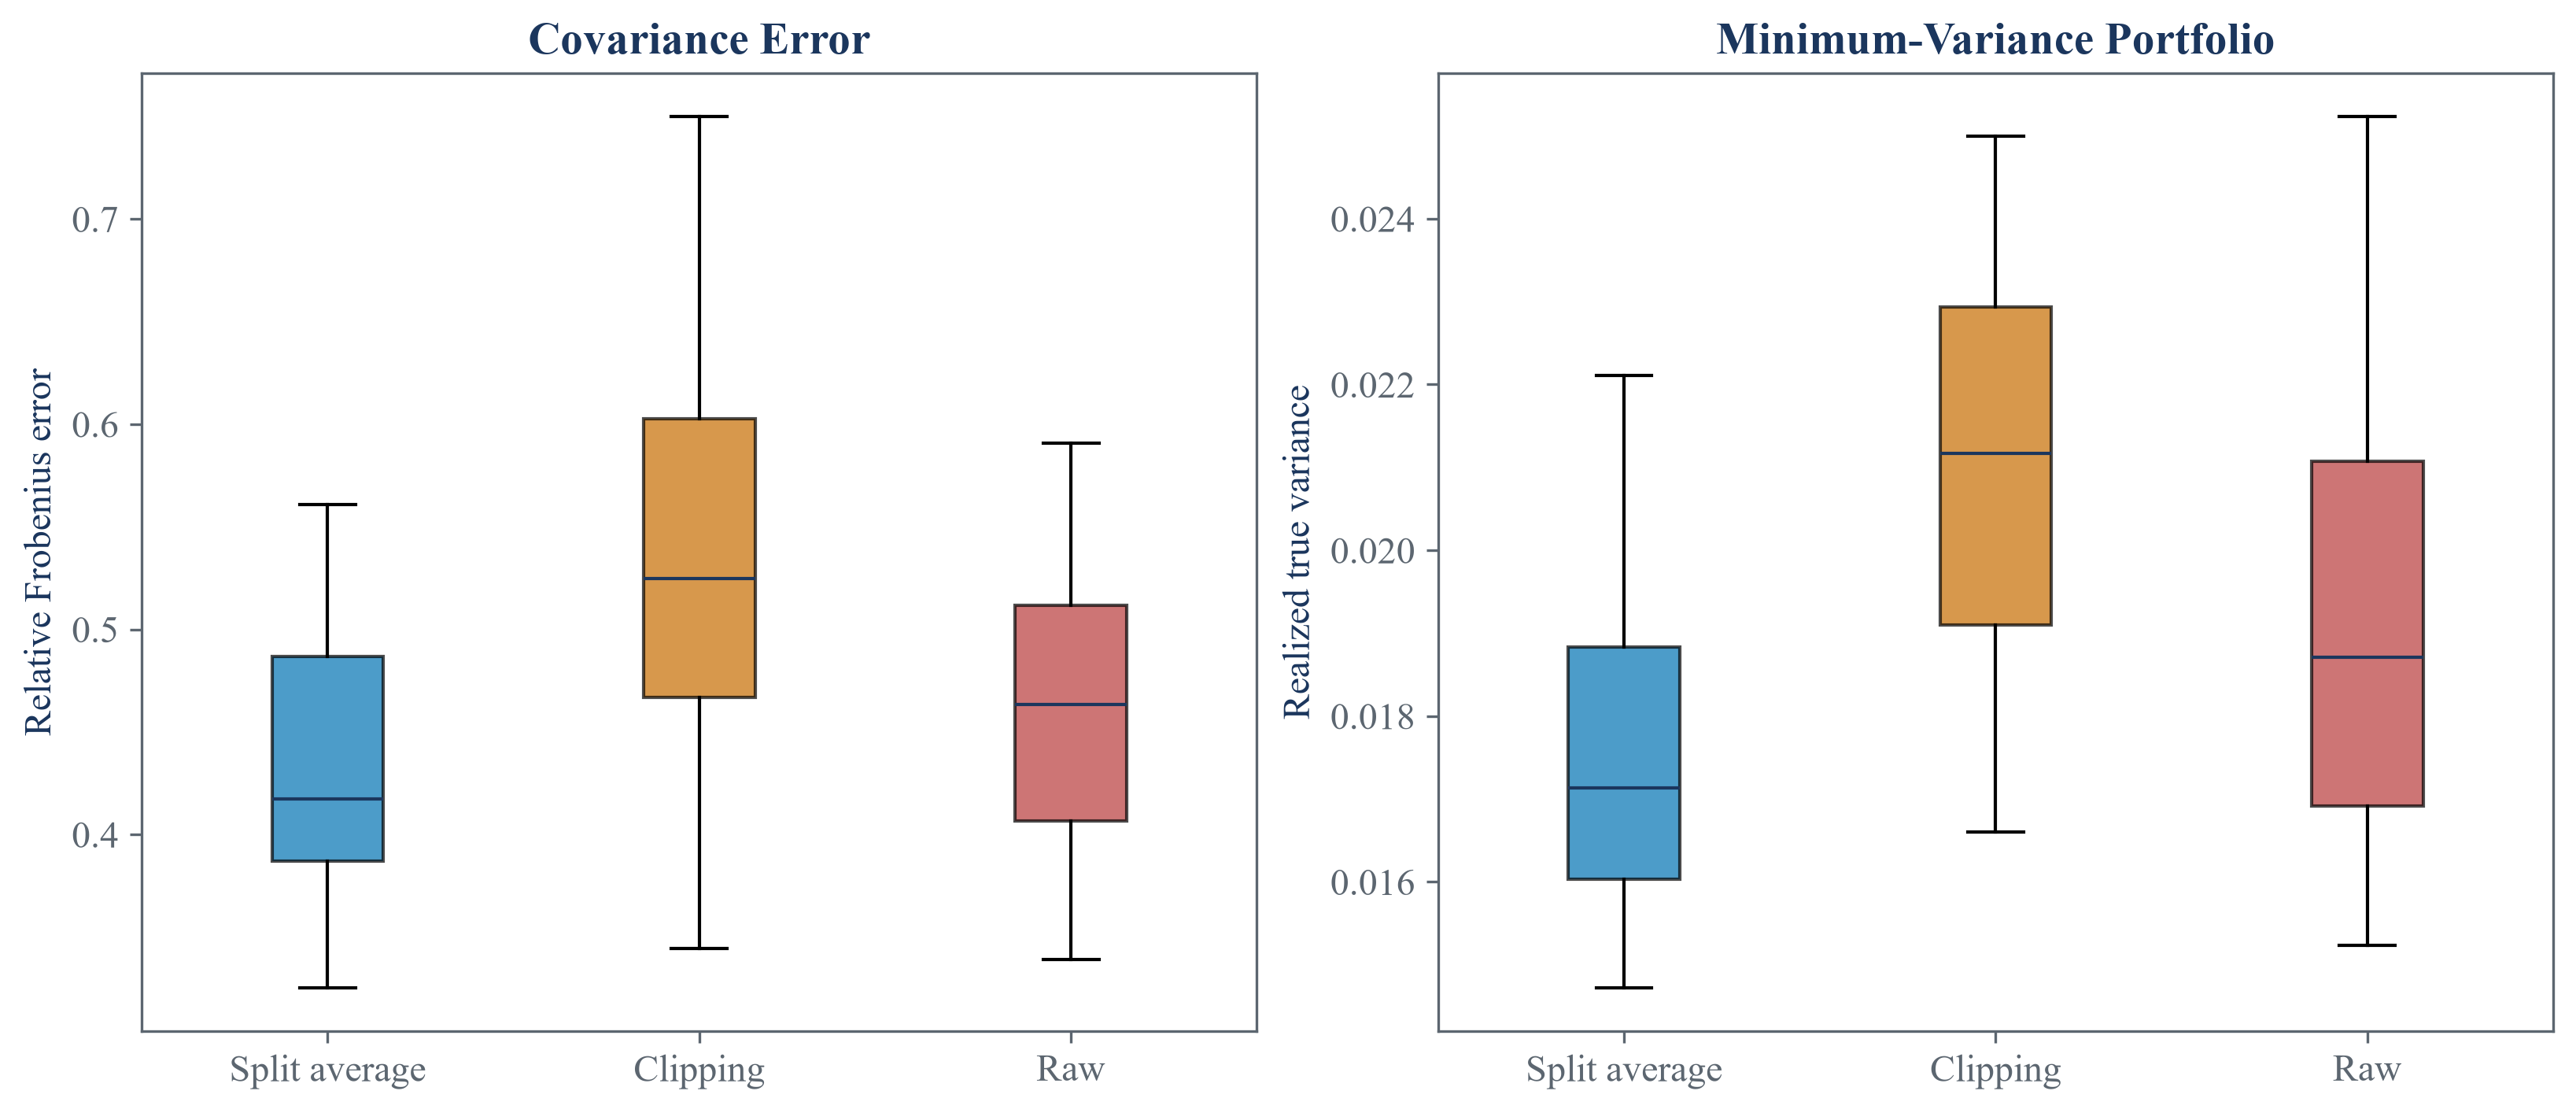

In [5]:
no_gap_dimension = 12
no_gap_observations = 30
no_gap_eigenvalues = np.asarray([1.4 ** (-index) for index in range(no_gap_dimension)])
no_gap_generator = np.random.default_rng(123)
no_gap_directions, _ = np.linalg.qr(no_gap_generator.standard_normal((no_gap_dimension, no_gap_dimension)))
no_gap_truth = no_gap_directions @ np.diag(no_gap_eigenvalues) @ no_gap_directions.T
no_gap_truth = (no_gap_truth + no_gap_truth.T) / 2.0
no_gap_cholesky = np.linalg.cholesky(no_gap_truth)
no_gap_rows = []
for repetition in range(40):
    simulated_returns = (no_gap_cholesky @ no_gap_generator.standard_normal((no_gap_dimension, no_gap_observations))).T
    sample_estimate = np.cov(simulated_returns, rowvar=False)
    nercome_estimate = nercome_denoised_covariance(simulated_returns, n_splits=100, random_state=repetition)
    clipping_estimate = denoise_cov(sample_estimate, no_gap_observations / no_gap_dimension, bandwidth=0.01)
    for method, estimate in [("NERCOME split average", nercome_estimate), ("Random-matrix clipping", clipping_estimate), ("Raw sample", sample_estimate)]:
        weights = optimal_portfolio(estimate)
        no_gap_rows.append({"Repetition": repetition + 1, "Method": method, "Relative covariance error": np.linalg.norm(estimate - no_gap_truth, ord="fro") / np.linalg.norm(no_gap_truth, ord="fro"), "Condition number": np.linalg.cond(estimate), "Realized true variance": float(weights.T @ no_gap_truth @ weights)})
no_gap_denoising_runs = pd.DataFrame(no_gap_rows)
no_gap_summary_rows = []
for method, group in no_gap_denoising_runs.groupby("Method", sort=False):
    no_gap_summary_rows.append({"Method": method, "Mean relative covariance error": group["Relative covariance error"].mean(), "Median relative covariance error": group["Relative covariance error"].median(), "Mean condition number": group["Condition number"].mean(), "Mean realized true variance": group["Realized true variance"].mean(), "Median realized true variance": group["Realized true variance"].median()})
no_gap_denoising_summary = pd.DataFrame(no_gap_summary_rows)
save_table(no_gap_denoising_summary, "no_gap_denoising_summary", "Covariance and portfolio error for a slowly decaying known spectrum.", "tab:chapter9-no-gap-denoising", fit=True)
display(no_gap_denoising_summary.round(6))

no_gap_methods = ["NERCOME split average", "Random-matrix clipping", "Raw sample"]
no_gap_colors = [palette["cyan"], palette["amber"], palette["rose"]]
figure, axes = plt.subplots(1, 2, figsize=(10.8, 4.6), constrained_layout=True)
error_box = axes[0].boxplot([no_gap_denoising_runs.loc[no_gap_denoising_runs["Method"] == method, "Relative covariance error"] for method in no_gap_methods], tick_labels=["Split average", "Clipping", "Raw"], patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
variance_box = axes[1].boxplot([no_gap_denoising_runs.loc[no_gap_denoising_runs["Method"] == method, "Realized true variance"] for method in no_gap_methods], tick_labels=["Split average", "Clipping", "Raw"], patch_artist=True, showfliers=False, medianprops={"color": palette["text"]})
for patch, color in zip(error_box["boxes"], no_gap_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.70)
for patch, color in zip(variance_box["boxes"], no_gap_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.70)
axes[0].set_title("Covariance Error")
axes[0].set_ylabel("Relative Frobenius error")
axes[1].set_title("Minimum-Variance Portfolio")
axes[1].set_ylabel("Realized true variance")
figure.savefig(FIGURES / "no_gap_denoising.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "no_gap_denoising.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "no_gap_denoising.png")))
plt.close(figure)

## Tests

In [6]:
assert data_hash == "8F394FE34BEA54D41B9AAFED410425EE8F8E252EDE3C71A7C1CD20BAB83040DE"
assert snapshot.shape == (125, 49)
assert q_ratio > 1.0
assert 0.0 < fitted_variance < 1.0
assert 0.0 < lambda_min < lambda_max
assert signal_count + noise_count == 49
assert signal_count >= 1
assert np.allclose(constant_correlation, constant_correlation.T)
assert np.allclose(np.diag(constant_correlation), 1.0)
assert np.allclose(np.diag(targeted_full_correlation), 1.0)
assert np.allclose(np.diag(targeted_half_correlation), 1.0)
assert np.allclose(targeted_half_correlation, 0.5 * targeted_full_correlation + 0.5 * sample_correlation)
assert np.isclose(np.trace(constant_correlation), 49.0)
assert np.isclose(np.trace(targeted_half_correlation), 49.0)
assert np.linalg.cond(constant_correlation) < np.linalg.cond(sample_correlation)
assert len(simulation_results) == 120
assert set(simulation_results["Method"]) == {"Sample", "Constant residual", "Targeted, alpha 0.5"}
assert np.allclose(np.diag(true_correlation), 1.0)
assert known_truth_denoising_summary["Mean relative error"].notna().all()
assert known_truth_denoising_summary.loc[known_truth_denoising_summary["Method"] == "Constant residual", "Mean condition number"].iloc[0] < known_truth_denoising_summary.loc[known_truth_denoising_summary["Method"] == "Sample", "Mean condition number"].iloc[0]
no_gap_indexed = no_gap_denoising_summary.set_index("Method")
assert len(no_gap_denoising_runs) == 120
assert np.all(np.linalg.eigvalsh(no_gap_truth) > 0.0)
assert no_gap_indexed.loc["NERCOME split average", "Mean relative covariance error"] < no_gap_indexed.loc["Random-matrix clipping", "Mean relative covariance error"]
assert no_gap_indexed.loc["NERCOME split average", "Mean realized true variance"] < no_gap_indexed.loc["Random-matrix clipping", "Mean realized true variance"]
assert (FIGURES / "mp_noise_bulk.pdf").is_file()
assert (FIGURES / "denoised_correlation_matrices.pdf").is_file()
assert (FIGURES / "no_gap_denoising.pdf").is_file()
assert (TABLES / "mp_fit_summary.tex").is_file()
assert (TABLES / "denoising_matrix_summary.tex").is_file()
assert (TABLES / "known_truth_denoising_summary.tex").is_file()
assert (TABLES / "no_gap_denoising_summary.tex").is_file()